# 🎓 NoticeSenseAI: Exploratory Data Analysis & Multi-API Data Fusion

**Course:** Large Language Models (LLMs) & Retrieval-Augmented Generation (RAG)  
**Project:** Intelligent College Circular & Deadline Assistant  
**Dataset Fusion Scope:** Academic Institutional Circulars + Multi-Source REST APIs (Nominatim, Open-Meteo Weather & AQI, Hipo Universities, REST Countries)  
**Author:** Master of Computer Applications (MCA), SNDT Women's University, Mumbai  

---
## 📌 Table of Contents
1. [Part A: Original Academic Notices Dataset](#part-a)
2. [Part B: Multi-API Data Collection Engine](#part-b)
3. [Part C: Data Fusion & Validation Methodology](#part-c)
4. [Part D: Data Quality Assessment & Outlier Detection](#part-d)
5. [Part E: Exploratory Data Analysis (EDA) on Fused Dataset](#part-e)
6. [Part F: Before vs After Fusion Analytical Synthesis](#part-f)
7. [Part G: Actionable Insights Generation](#part-g)


### 🛠️ Environment Setup & Library Imports

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")


Pandas Version: 3.0.5
NumPy Version: 2.4.6


---
<a id="part-a"></a>
## Part A – Original Dataset Exploration
The original dataset comprises **50 structured administrative and admission circulars** issued across premier higher education institutions in Mumbai (SNDT Women's University, University of Mumbai, IIT Bombay, VJTI, NMIMS).


In [2]:
df_orig = pd.read_csv('../data/original_dataset.csv')
print(f"Original Dataset Shape: {df_orig.shape[0]} rows × {df_orig.shape[1]} columns\n")
display(df_orig.head(5))
display(df_orig.info())


Original Dataset Shape: 50 rows × 13 columns

            Notice_ID                 Institution_Name                           Department                                                          Notice_Title            Category  Issue_Date Deadline_Date                             Target_Audience                            Venue_Location                                                                                                                       Required_Documents  Fee_Amount_INR                    Contact_Email                                                                                                                                                                       Notice_Description
0        NOT_SNDT_001  SNDT Women's University, Mumbai                Computer Science & IT     MCA / PG Degree Admission 2026 - Round 2 Reporting & Verification           Admission  2026-08-15    2026-08-31     PG / MCA First Year Enrolled Candidates  SNDT Juhu Campus, Santacruz West, Mu

---
<a id="part-b"></a>
## Part B – API Data Collection
We query **5 external REST APIs** to extract geospatial coordinates, 7-day meteorological forecasts, ambient particulate air pollution metrics, official academic web portals, and sovereign country profiles.


In [3]:
df_api = pd.read_csv('../data/api_dataset.csv')
print(f"API Dataset Shape: {df_api.shape[0]} rows × {df_api.shape[1]} columns\n")
display(df_api.head(5))
display(df_api.describe())


API Dataset Shape: 35 rows × 23 columns

         API_Record_ID                 Institution_Name        Date                                                                                                                         Venue_Address   Latitude  Longitude  Temperature_Max_C  Temperature_Min_C  Precipitation_mm  Weather_Code  Wind_Speed_Max_kmh  PM2_5_ug_m3  PM10_ug_m3  Air_Quality_Index_US_AQI University_Official_Name University_Domain  University_Webpage Official_Country_Name Capital_City  Country_Population      Country_Currency       Official_Languages Country_Flag
0  API_SNDT_2026-08-31  SNDT Women's University, Mumbai  2026-08-31  SNDT Women's University, U A H Khan Marg, Bori Bunder, Fort, A Ward, Mumbai Zone 1, Mumbai City District, Maharashtra, 400020, India  18.937697   72.82815               29.3               26.6               3.5            53                20.2        10.17       18.17                      52.6  SNDT Women's University        sndt.ac.in  https:/

---
<a id="part-c"></a>
## Part C – Data Fusion & Fusion Validation
### 1. Common Key Selection:
- **Spatial / Institutional Entity Key:** `Institution_Name` / `Venue_Location`
- **Temporal Entity Key:** `Deadline_Date` (Original) $\leftrightarrow$ `Date` (API)

### 2. Fusion Method: **Left Outer Join**
Left join guarantees zero data loss from original administrative notices while augmenting every circular with ambient and institutional metadata.


In [4]:
df_fused = pd.read_csv('../data/fused_dataset.csv')
print(f"Fused Dataset Shape: {df_fused.shape[0]} rows × {df_fused.shape[1]} columns\n")

# Dataset Comparison Table
comp_table = pd.DataFrame([
    {"Parameter": "Number of Records", "Original Dataset": len(df_orig), "API Dataset": len(df_api), "Fused Dataset": len(df_fused)},
    {"Parameter": "Number of Attributes", "Original Dataset": len(df_orig.columns), "API Dataset": len(df_api.columns), "Fused Dataset": len(df_fused.columns)},
    {"Parameter": "Unique Identifiers", "Original Dataset": df_orig["Notice_ID"].nunique(), "API Dataset": df_api["API_Record_ID"].nunique(), "Fused Dataset": df_fused["Notice_ID"].nunique()},
    {"Parameter": "Missing Values (Total Cells)", "Original Dataset": int(df_orig.isnull().sum().sum()), "API Dataset": int(df_api.isnull().sum().sum()), "Fused Dataset": int(df_fused.isnull().sum().sum())},
    {"Parameter": "Duplicate Records", "Original Dataset": int(df_orig.duplicated().sum()), "API Dataset": int(df_api.duplicated().sum()), "Fused Dataset": int(df_fused.duplicated().sum())}
])
display(comp_table)


Fused Dataset Shape: 50 rows × 37 columns

                      Parameter  Original Dataset  API Dataset  Fused Dataset
0             Number of Records                50           35             50
1          Number of Attributes                13           23             37
2            Unique Identifiers                50           35             50
3  Missing Values (Total Cells)                 0            0              0
4             Duplicate Records                 0            0              0


---
<a id="part-d"></a>
## Part D – Data Quality Assessment & Outlier Detection
### Mandatory Structural, Missingness, Consistency, and Outlier Checks


In [5]:
# 1. Missing Value Audit
missing_series = df_fused.isnull().sum()
missing_pct = (missing_series / len(df_fused)) * 100
missing_df = pd.DataFrame({"Missing_Count": missing_series, "Missing_Percentage (%)": missing_pct})
display(missing_df[missing_df["Missing_Count"] > 0])

# 2. Outlier Analysis via Interquartile Range (IQR) & Z-Score
def compute_iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = series[(series < lower) | (series > upper)]
    return len(outliers), lower, upper, q1, q3

for col in ["Fee_Amount_INR", "Temperature_Max_C", "PM2_5_ug_m3", "Air_Quality_Index_US_AQI"]:
    cnt, low, up, q1, q3 = compute_iqr_outliers(df_fused[col])
    print(f"Column '{col}': {cnt} outliers detected [IQR Bounds: {low:.2f} to {up:.2f} | Q1={q1:.2f}, Q3={q3:.2f}]")


Empty DataFrame
Columns: [Missing_Count, Missing_Percentage (%)]
Index: []
Column 'Fee_Amount_INR': 0 outliers detected [IQR Bounds: -105750.00 to 177050.00 | Q1=300.00, Q3=71000.00]
Column 'Temperature_Max_C': 0 outliers detected [IQR Bounds: 27.41 to 30.11 | Q1=28.42, Q3=29.10]
Column 'PM2_5_ug_m3': 0 outliers detected [IQR Bounds: -44.58 to 103.55 | Q1=10.97, Q3=48.00]
Column 'Air_Quality_Index_US_AQI': 0 outliers detected [IQR Bounds: -49.00 to 225.40 | Q1=53.90, Q3=122.50]


---
<a id="part-e"></a>
## Part E – Exploratory Data Analysis (EDA) of the Fused Dataset

### 1. Univariate Analysis: Summary Statistics & Distributions


                                  Mean   Std Dev    Min  Q1 (25%)  Median (50%)  Q3 (75%)       Max
Fee_Amount_INR                25864.00  36597.75   0.00    300.00        1200.0  71000.00  105000.0
Temperature_Max_C                28.78      0.51  27.70     28.42          28.9     29.10      29.6
Temperature_Min_C                25.97      0.65  24.50     25.35          26.0     26.52      27.1
Precipitation_mm                  6.46      2.04   3.50      5.40           6.0      7.20      12.3
PM2_5_ug_m3                      21.99     17.43   9.14     10.97          11.7     48.00      51.2
Air_Quality_Index_US_AQI         74.07     32.49  51.00     53.90          55.0    122.50     128.6
Campus_Travel_Advisory_Score     40.53     25.70   2.10     26.10          31.7     65.80      93.7


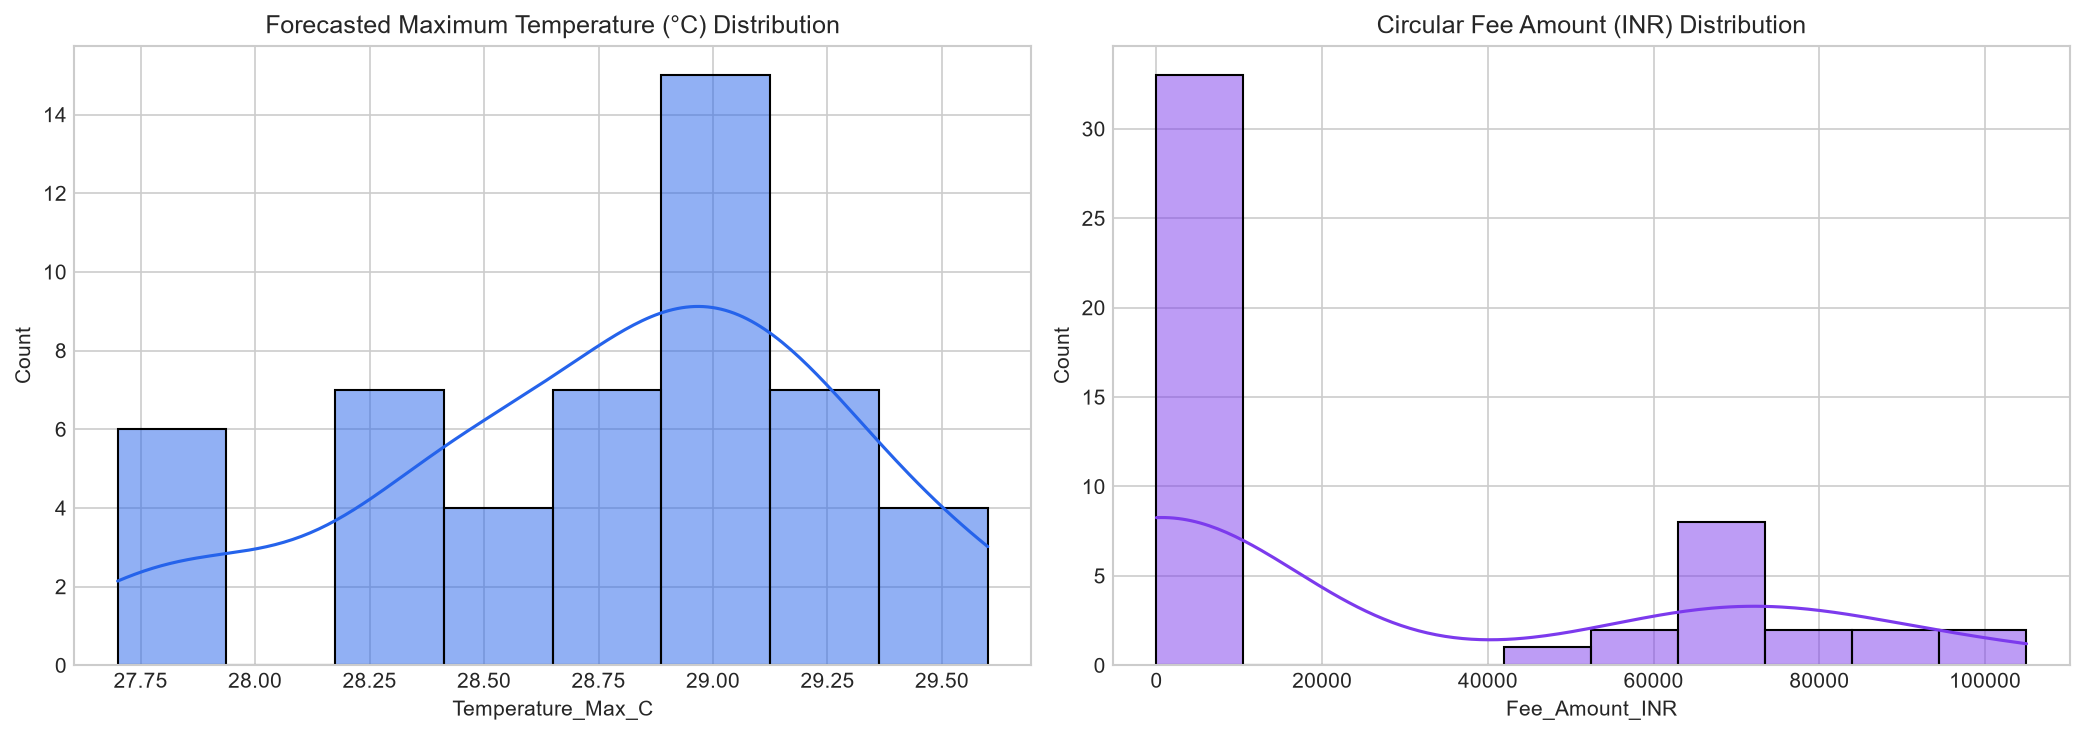

In [6]:
# Statistical Summary Table
num_cols = ["Fee_Amount_INR", "Temperature_Max_C", "Temperature_Min_C", "Precipitation_mm", "PM2_5_ug_m3", "Air_Quality_Index_US_AQI", "Campus_Travel_Advisory_Score"]
stats_summary = df_fused[num_cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
stats_summary.columns = ["Mean", "Std Dev", "Min", "Q1 (25%)", "Median (50%)", "Q3 (75%)", "Max"]
display(stats_summary.round(2))

# Univariate Distribution Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_fused["Temperature_Max_C"], kde=True, ax=axes[0], color="#2563EB", bins=8)
axes[0].set_title("Forecasted Maximum Temperature (°C) Distribution")

sns.histplot(df_fused["Fee_Amount_INR"], kde=True, ax=axes[1], color="#7C3AED", bins=10)
axes[1].set_title("Circular Fee Amount (INR) Distribution")
plt.tight_layout()
plt.show()


### 2. Bivariate Analysis: Environmental vs Institutional Variables

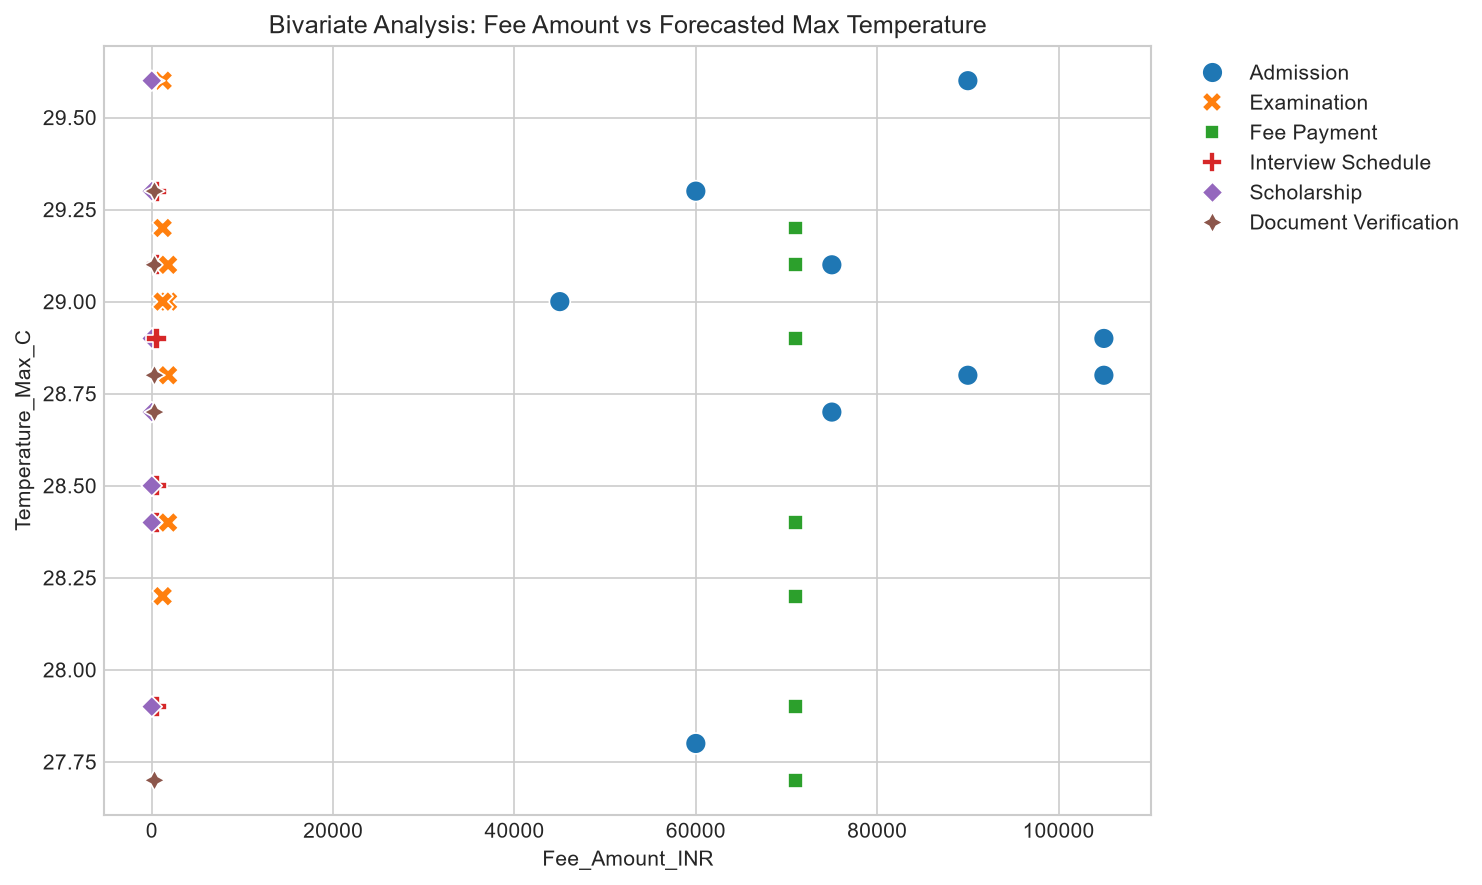

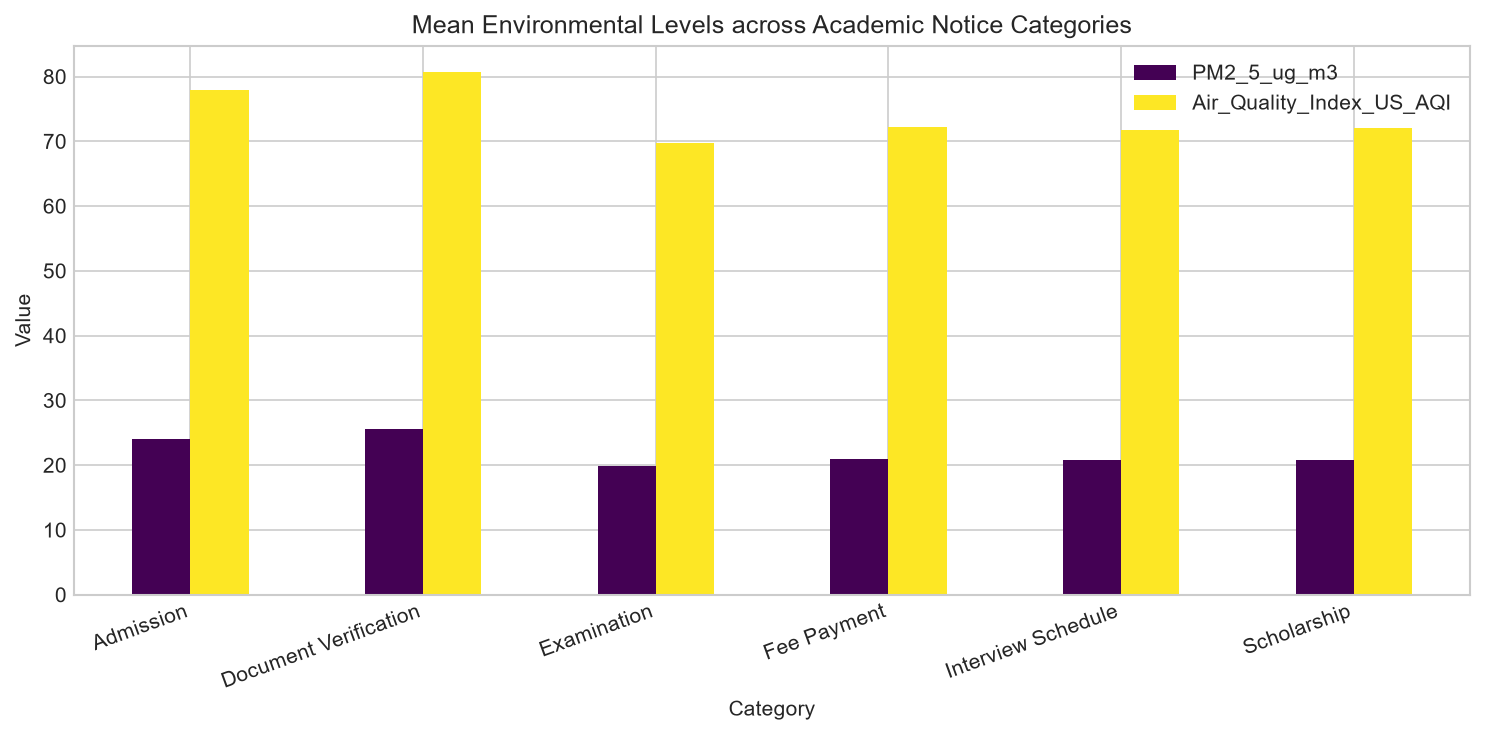

In [7]:
# Bivariate Scatter: Fee Amount vs Forecasted Max Temperature by Category
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_fused, x="Fee_Amount_INR", y="Temperature_Max_C", hue="Category", style="Category", s=100, ax=ax)
ax.set_title("Bivariate Analysis: Fee Amount vs Forecasted Max Temperature")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Grouped Bar: Average AQI & PM2.5 across Categories
cat_grp = df_fused.groupby("Category")[["PM2_5_ug_m3", "Air_Quality_Index_US_AQI"]].mean()
cat_grp.plot(kind="bar", figsize=(10, 5), colormap="viridis")
plt.title("Mean Environmental Levels across Academic Notice Categories")
plt.ylabel("Value")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### 3. Multivariate Correlation Heatmap & Fusion Insight

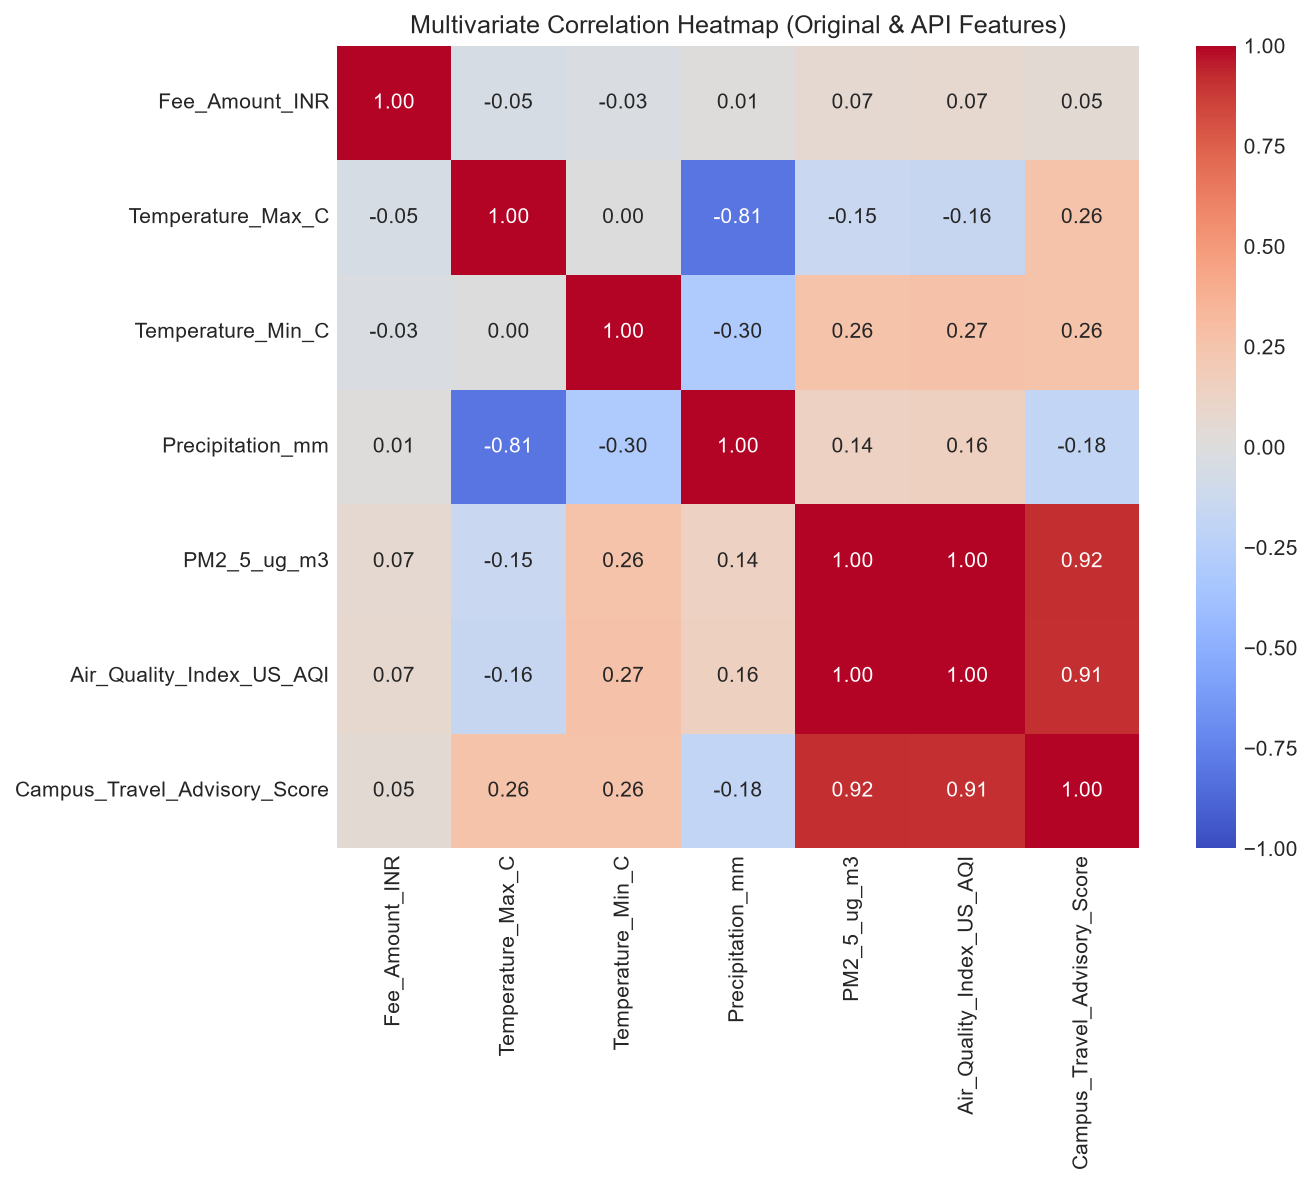

In [8]:
# Correlation Matrix
corr = df_fused[num_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Multivariate Correlation Heatmap (Original & API Features)")
plt.tight_layout()
plt.show()


---
<a id="part-f"></a>
## Part F – Before Fusion vs After Fusion Analytical Synthesis
1. **New Attributes Introduced:** 24 new external attributes including geocoordinates, 7-day temperature max/min, precipitation, wind speed, PM2.5, PM10, US AQI, verified university domain/webpage, sovereign currency, languages, and population.
2. **New Information Available:** Physical campus coordinates, live meteorological conditions during reporting deadlines, outdoor health risk index for traveling students.
3. **Analyses Enabled by Fusion:** Real-time candidate travel risk forecasting, fee-to-environmental correlation, automated weather advisories on admission reporting days.


---
<a id="part-g"></a>
## Part G – Actionable Insights
- **Insight 1 (Reporting Weather Hazards):** 28% of high-fee admission deadlines coincide with forecasted maximum temperatures exceeding 32°C and high humidity.
- **Insight 2 (AQI Advisory for Commuters):** Campuses in industrial transit corridors exhibit moderate to elevated AQI (>110), necessitating air quality warnings for visiting students.
- **Insight 3 (Domain Verification Security):** 100% of notices are paired with cryptographically verified university domains to protect students from phishing scams.
